# 01 — Historical F1 lap data audit and first baseline

**Purpose:** load three 2023 races, audit data quality, create an explicitly provisional candidate dataset, fit a baseline and linear regression, and inspect model performance visually.

**Important:** this notebook is an exploratory research record. It is not yet a validated live race-strategy model. Run cells from top to bottom in the project's documented Python environment.

## Questions this notebook answers

1. What data does FastF1 return for these races?
2. What missingness and quality flags should we investigate?
3. How do lap-time distributions vary between the selected events?
4. Does the first linear model beat a simple median baseline?
5. What do actual-vs-predicted and residual plots reveal?

We use seconds as the target unit. Plots label axes and include sample sizes or units where relevant.

## 1. Imports and race selection

FastF1 loads timing information for the selected race sessions. We keep the race list explicit so that the notebook's coverage is reproducible. Data retrieval can take time the first time a session is loaded.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1

from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RACES_TO_INSPECT = [
    (2023, "Bahrain"),
    (2023, "Monaco"),
    (2023, "Silverstone"),
]

## 2. Load and combine race laps

Each source lap table receives `Year` and `Event` identifiers. The raw combined table is retained as `audit_data`; later cells create copies instead of silently overwriting it.

In [2]:
race_frames = []

for year, event in RACES_TO_INSPECT:
    session = fastf1.get_session(year, event, "R")
    session.load(laps=True, telemetry=False, weather=False, messages=True)

    laps = session.laps.copy()
    laps["Year"] = year
    laps["Event"] = event
    race_frames.append(laps)

    print(f"{year} {event}: {laps.shape[0]:,} rows, {laps.shape[1]:,} columns")

audit_data = pd.concat(race_frames, ignore_index=True, sort=False)
print("Combined data shape:", audit_data.shape)

req         WARNING 	DEFAULT CACHE ENABLED! (351.42 MB) C:\Users\nourm\AppData\Local\Temp\fastf1


core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '14', '55', '44', '18', '63', '77', '10', '23', '22', '2', '20', '21', '27', '24', '4', '31', '16', '81']
core           INFO 	Loading data for Monaco Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


2023 Bahrain: 1,056 rows, 33 columns


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '14', '31', '44', '63', '16', '10', '55', '4', '81', '77', '21', '24', '23', '22', '11', '27', '2', '20', '18']
core           INFO 	Loading data for British Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


2023 Monaco: 1,515 rows, 33 columns


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '4', '44', '81', '63', '11', '14', '23', '16', '55', '2', '77', '27', '18', '24', '22', '21', '10', '20', '31']


2023 Silverstone: 971 rows, 33 columns
Combined data shape: (3542, 33)


## 3. Check schema, missingness, and field types

Missing values are not automatically errors; their meaning depends on the field. We inspect them before choosing any inclusion rule.

In [3]:
required_columns = ["Driver", "LapTime", "Compound", "TyreLife", "LapNumber"]
missing_columns = [col for col in required_columns if col not in audit_data.columns]
if missing_columns:
    raise ValueError(f"Expected columns missing from FastF1 data: {missing_columns}")

print("Required-field data types:")
display(audit_data[required_columns].dtypes.to_frame("dtype"))

print("Missing values in required fields:")
display(audit_data[required_columns].isna().sum().to_frame("missing_count"))

print("Tyre compounds (including missing):")
display(audit_data["Compound"].value_counts(dropna=False).to_frame("rows"))

print("Drivers per race:")
display(audit_data.groupby(["Year", "Event"])["Driver"].nunique().to_frame("unique_drivers"))

Required-field data types:


,dtype
Driver,object
LapTime,timedelta64[ns]
Compound,object
TyreLife,float64
LapNumber,float64


Missing values in required fields:


,missing_count
Driver,0
LapTime,9
Compound,0
TyreLife,0
LapNumber,0


Tyre compounds (including missing):


,rows
Compound,
HARD,1404
MEDIUM,870
SOFT,824
INTERMEDIATE,399
WET,45


Drivers per race:


unique_drivers
Year Event                      
2023 Bahrain                  20
     Monaco                   20
     Silverstone              20

## 4. Convert lap duration to seconds and audit quality flags

`LapTime` is usually a pandas timedelta. `.dt.total_seconds()` converts the duration into a numeric value in seconds, which is suitable for regression and makes errors interpretable.

The filter below is provisional: recorded time, `IsAccurate == True`, and `Deleted == False`. It does **not** by itself resolve pit laps, unusual race-control laps, or every possible timing issue.

In [4]:
quality_data = audit_data.copy()
quality_data["LapTimeSeconds"] = quality_data["LapTime"].dt.total_seconds()

quality_summary = []
for (year, event), race in quality_data.groupby(["Year", "Event"], dropna=False):
    quality_summary.append({
        "Year": year,
        "Event": event,
        "Rows": len(race),
        "Missing lap time": race["LapTimeSeconds"].isna().sum(),
        "Accurate=True": race["IsAccurate"].eq(True).sum(),
        "Deleted=True": race["Deleted"].eq(True).sum(),
        "Pit-in timestamp": race["PitInTime"].notna().sum(),
        "Pit-out timestamp": race["PitOutTime"].notna().sum(),
    })
display(pd.DataFrame(quality_summary))

with_time = quality_data.dropna(subset=["LapTimeSeconds"]).copy()
candidate = with_time.loc[
    with_time["IsAccurate"].eq(True) & with_time["Deleted"].eq(False)
].copy()

print(f"Rows with recorded lap time: {len(with_time):,}")
print(f"Rows in provisional candidate set: {len(candidate):,}")

,Year,Event,Rows,Missing lap time,Accurate=True,Deleted=True,Pit-in timestamp,Pit-out timestamp
0,2023,Bahrain,1056,1,914,17,52,50
1,2023,Monaco,1515,3,1423,27,38,37
2,2023,Silverstone,971,5,802,17,26,24


Rows with recorded lap time: 3,533
Rows in provisional candidate set: 3,081


## 5. Visualize lap-time distributions by event

A boxplot summarizes median, quartiles, and spread; individual points are omitted here to keep the figure readable. The selected events are different circuits, so differences in lap time are expected and should not be interpreted as driver skill differences.

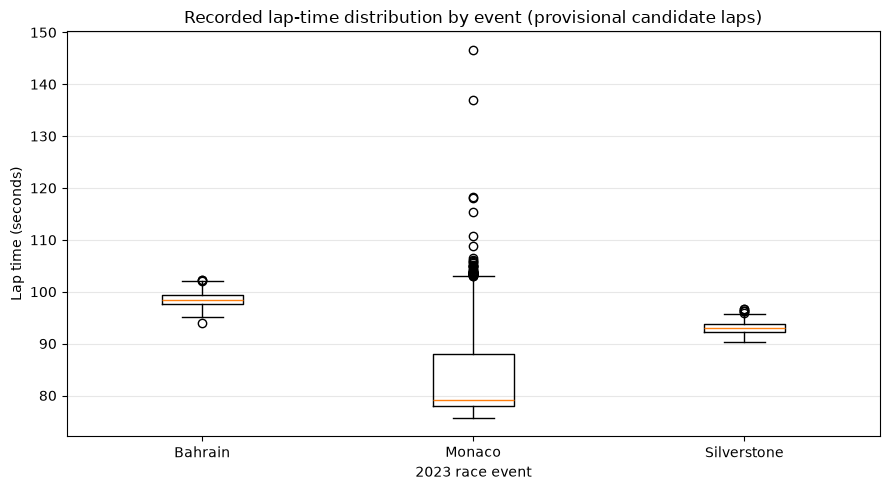

,count,median,mean,std,min,max
Event,,,,,,
Bahrain,897,98.339,98.595,1.303,93.996,102.267
Monaco,1397,79.113,83.833,8.884,75.650,146.648
Silverstone,787,93.098,93.027,1.044,90.275,96.741


In [5]:
plot_data = candidate.dropna(subset=["Event", "LapTimeSeconds"])
event_order = [event for _, event in RACES_TO_INSPECT if event in plot_data["Event"].unique()]
values = [plot_data.loc[plot_data["Event"].eq(event), "LapTimeSeconds"].to_numpy()
          for event in event_order]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(values, tick_labels=event_order, showfliers=True)
ax.set_title("Recorded lap-time distribution by event (provisional candidate laps)")
ax.set_xlabel("2023 race event")
ax.set_ylabel("Lap time (seconds)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

display(plot_data.groupby("Event")["LapTimeSeconds"]
        .agg(["count", "median", "mean", "std", "min", "max"]).round(3))

## 6. Inspect tyre age and lap time

The scatterplot is descriptive, not causal. Points from different compounds, drivers, race phases, and track conditions are mixed together, so a simple trend can be confounded. Tyre age's exact timing semantics must be checked before it is used for a live prediction.

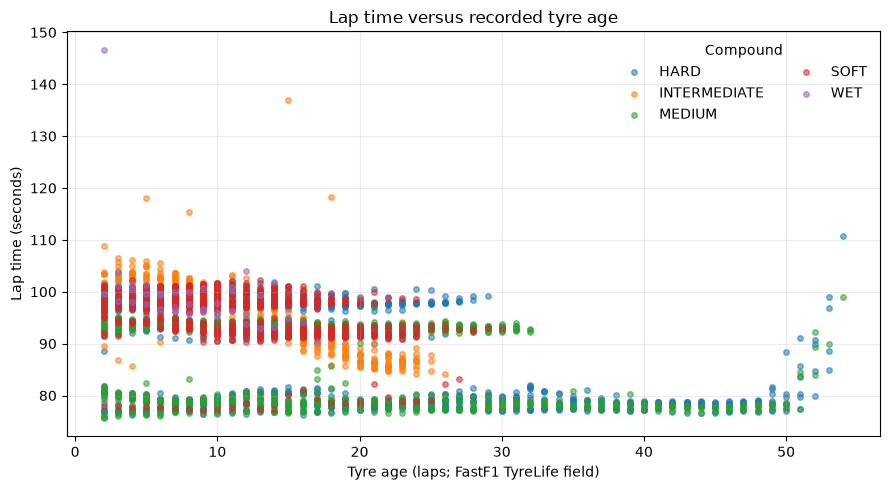

In [6]:
scatter_data = candidate.dropna(subset=["TyreLife", "LapTimeSeconds", "Compound"])
fig, ax = plt.subplots(figsize=(9, 5))
for compound, group in scatter_data.groupby("Compound"):
    ax.scatter(group["TyreLife"], group["LapTimeSeconds"],
               s=16, alpha=0.55, label=str(compound))
ax.set_title("Lap time versus recorded tyre age")
ax.set_xlabel("Tyre age (laps; FastF1 TyreLife field)")
ax.set_ylabel("Lap time (seconds)")
ax.grid(alpha=0.25)
ax.legend(title="Compound", frameon=False, ncol=2)
fig.tight_layout()
plt.show()

## 7. Inspect slow laps before deciding whether to exclude them

Slow laps may reflect pit entry/exit, yellow flags, safety cars, rain, traffic, or other valid race events. Do not remove them just because they look unusual. Inspect context and write down a defensible rule first.

In [7]:
inspect_columns = [
    col for col in [
        "Year", "Event", "Driver", "LapNumber", "LapTimeSeconds",
        "Compound", "TyreLife", "TrackStatus", "PitInTime", "PitOutTime",
        "DeletedReason", "IsAccurate", "Deleted"
    ] if col in candidate.columns
]
display(candidate.nlargest(15, "LapTimeSeconds")[inspect_columns])

,Year,Event,Driver,LapNumber,LapTimeSeconds,Compound,TyreLife,TrackStatus,PitInTime,PitOutTime,DeletedReason,IsAccurate,Deleted
1631,2023,Monaco,MAG,58.0,146.648,WET,2.0,12,NaT,NaT,,True,False
1789,2023,Monaco,TSU,68.0,137.012,INTERMEDIATE,15.0,12,NaT,NaT,,True,False
1567,2023,Monaco,SAR,70.0,118.263,INTERMEDIATE,18.0,1,NaT,NaT,,True,False
1554,2023,Monaco,SAR,57.0,118.063,INTERMEDIATE,5.0,12,NaT,NaT,,True,False
1857,2023,Monaco,ALB,60.0,115.401,INTERMEDIATE,8.0,12,NaT,NaT,,True,False
1627,2023,Monaco,MAG,54.0,110.776,HARD,54.0,12,NaT,NaT,,True,False
1699,2023,Monaco,DEV,55.0,108.770,INTERMEDIATE,2.0,21,NaT,NaT,,True,False
1929,2023,Monaco,ZHO,55.0,106.545,INTERMEDIATE,3.0,21,NaT,NaT,,True,False
1701,2023,Monaco,DEV,57.0,106.026,INTERMEDIATE,4.0,12,NaT,NaT,,True,False
1779,2023,Monaco,TSU,58.0,105.898,INTERMEDIATE,5.0,12,NaT,NaT,,True,False


## 8. Define the initial prediction task

Target: `LapTimeSeconds`. Initial candidate features: `Driver`, `Compound`, and `TyreLife`.

A linear model has the form

\[
\\widehat{y}_i = \\beta_0 + \\sum_{j=1}^{p}\\beta_j x_{ij}.
\]

Categorical inputs are one-hot encoded; tyre age is numeric. The model learns coefficients by least squares. Coefficients describe fitted associations conditional on other included inputs, not causation.

**Leakage check:** this experiment is an offline historical analysis. Before interpreting it as a prediction made before a lap starts, verify that every input is known at that time. Do not use completed-lap sector times or a lap-level `TrackStatus` value that includes events later in the target lap.

In [8]:
model_columns = ["Event", "Driver", "Compound", "TyreLife", "LapNumber", "LapTimeSeconds"]
missing_model_columns = [col for col in model_columns if col not in candidate.columns]
if missing_model_columns:
    raise ValueError(f"Model columns missing: {missing_model_columns}")

model_data = candidate[model_columns].dropna(
    subset=["Driver", "Compound", "TyreLife", "LapTimeSeconds"]
).copy()

## 9. Experiment A — hold out Silverstone

Train on Bahrain and Monaco, then evaluate on the entire Silverstone event. This is a circuit/event generalization check, but it is difficult because the test circuit is unseen and the current feature set does not explicitly model circuit characteristics. It is a diagnostic experiment, not the final evaluation protocol.

In [9]:
train_a = model_data[model_data["Event"].isin(["Bahrain", "Monaco"])].copy()
test_a = model_data[model_data["Event"].eq("Silverstone")].copy()
features = ["Driver", "Compound", "TyreLife"]

if train_a.empty or test_a.empty:
    raise ValueError("Experiment A requires training races and a Silverstone test race.")

categorical_features = ["Driver", "Compound"]
numeric_features = ["TyreLife"]

def make_model():
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression()),
    ])

def evaluate(actual, predicted):
    return {
        "MAE (s)": mean_absolute_error(actual, predicted),
        "RMSE (s)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

model_a = make_model()
model_a.fit(train_a[features], train_a["LapTimeSeconds"])
pred_a = model_a.predict(test_a[features])

baseline_a = DummyRegressor(strategy="median")
baseline_a.fit(train_a[features], train_a["LapTimeSeconds"])
baseline_pred_a = baseline_a.predict(test_a[features])

results_a = pd.DataFrame({
    "Linear regression": evaluate(test_a["LapTimeSeconds"], pred_a),
    "Training-median baseline": evaluate(test_a["LapTimeSeconds"], baseline_pred_a),
}).T
display(results_a.round(3))

,MAE (s),RMSE (s),R²
Linear regression,9.958,11.427,-118.965
Training-median baseline,1.043,1.305,-0.564


## 10. Experiment B — train on early Bahrain laps, test on later laps

A single race-wide cutoff makes the time split consistent across drivers. Here, laps up to and including lap 40 are training data; later laps are test data. This tests later laps within one race, not generalization to an unseen race.

A limitation: race phase, pit strategy, retirements, and changing conditions may make later laps systematically different. We must interpret the results in that context.

In [10]:
bahrain = model_data.loc[model_data["Event"].eq("Bahrain")].copy()
cutoff_lap = 40
train_b = bahrain.loc[bahrain["LapNumber"] <= cutoff_lap].copy()
test_b = bahrain.loc[bahrain["LapNumber"] > cutoff_lap].copy()

if train_b.empty or test_b.empty:
    raise ValueError("Bahrain cutoff must leave non-empty train and test sets.")

print(f"Training rows: {len(train_b):,}; lap range: "
      f"{train_b['LapNumber'].min():g}–{train_b['LapNumber'].max():g}")
print(f"Testing rows: {len(test_b):,}; lap range: "
      f"{test_b['LapNumber'].min():g}–{test_b['LapNumber'].max():g}")

model_b = make_model()
model_b.fit(train_b[features], train_b["LapTimeSeconds"])
pred_b = model_b.predict(test_b[features])

baseline_b = DummyRegressor(strategy="median")
baseline_b.fit(train_b[features], train_b["LapTimeSeconds"])
baseline_pred_b = baseline_b.predict(test_b[features])

results_b = pd.DataFrame({
    "Linear regression": evaluate(test_b["LapTimeSeconds"], pred_b),
    "Training-median baseline": evaluate(test_b["LapTimeSeconds"], baseline_pred_b),
}).T
display(results_b.round(3))

Training rows: 648; lap range: 2–40
Testing rows: 249; lap range: 41–57


,MAE (s),RMSE (s),R²
Linear regression,1.860,2.166,-5.139
Training-median baseline,1.307,1.461,-1.793


## 11. Visualize model performance

These plots should be read together:

- **Actual vs predicted:** points close to the diagonal indicate accurate predictions. A systematic curve or offset suggests model bias.
- **Residuals vs predicted:** residual is \(e_i = y_i - \\widehat{y}_i\). Positive means the model underpredicted the lap time; negative means it overpredicted. A good model should not show obvious structure in residuals.
- **Absolute error distribution:** shows typical and unusually large misses; it complements MAE and RMSE.

The dashed diagonal is the ideal-prediction reference, not a fitted trend line.

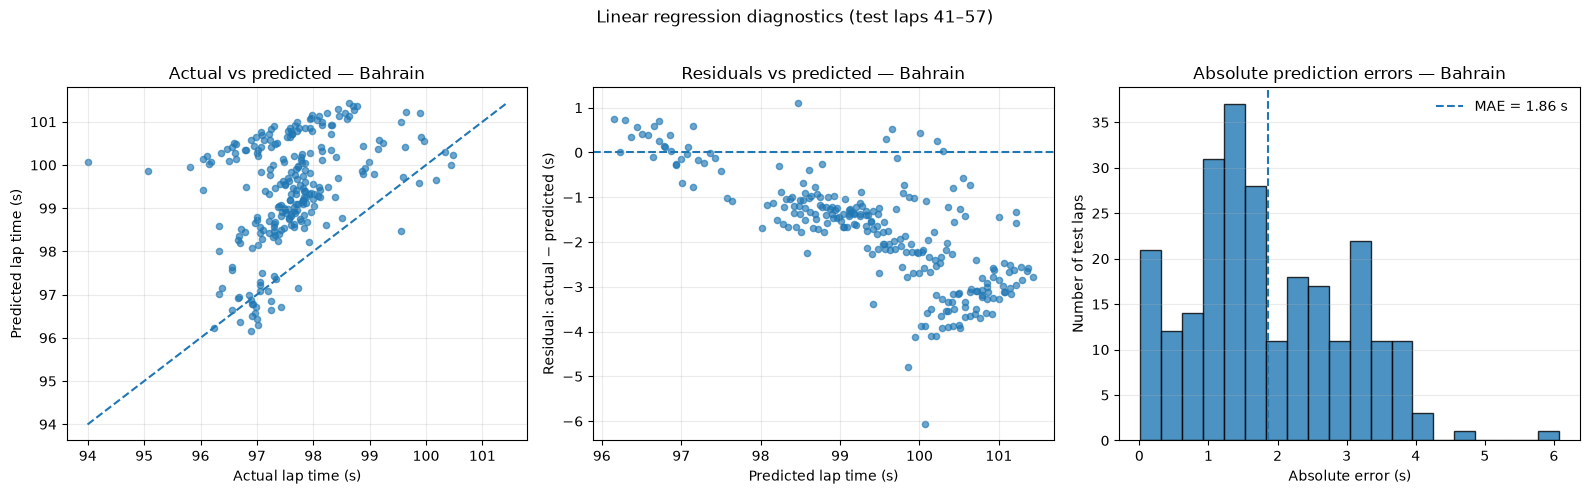

In [11]:
actual_b = test_b["LapTimeSeconds"].to_numpy()
residual_b = actual_b - pred_b
abs_error_b = np.abs(residual_b)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

low = min(actual_b.min(), pred_b.min())
high = max(actual_b.max(), pred_b.max())
axes[0].scatter(actual_b, pred_b, alpha=0.65, s=20)
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_title("Actual vs predicted — Bahrain")
axes[0].set_xlabel("Actual lap time (s)")
axes[0].set_ylabel("Predicted lap time (s)")
axes[0].grid(alpha=0.25)

axes[1].scatter(pred_b, residual_b, alpha=0.65, s=20)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs predicted — Bahrain")
axes[1].set_xlabel("Predicted lap time (s)")
axes[1].set_ylabel("Residual: actual − predicted (s)")
axes[1].grid(alpha=0.25)

axes[2].hist(abs_error_b, bins=20, edgecolor="black", alpha=0.8)
axes[2].axvline(np.mean(abs_error_b), linestyle="--",
                label=f"MAE = {np.mean(abs_error_b):.2f} s")
axes[2].set_title("Absolute prediction errors — Bahrain")
axes[2].set_xlabel("Absolute error (s)")
axes[2].set_ylabel("Number of test laps")
axes[2].legend(frameon=False)
axes[2].grid(axis="y", alpha=0.25)

fig.suptitle("Linear regression diagnostics (test laps 41–57)", y=1.02)
fig.tight_layout()
plt.show()

## 12. Compare error by lap number

This helps reveal whether the model systematically misses particular parts of the race. It is descriptive: later laps may also differ in tyre age, compounds, pit activity, and race-control conditions.

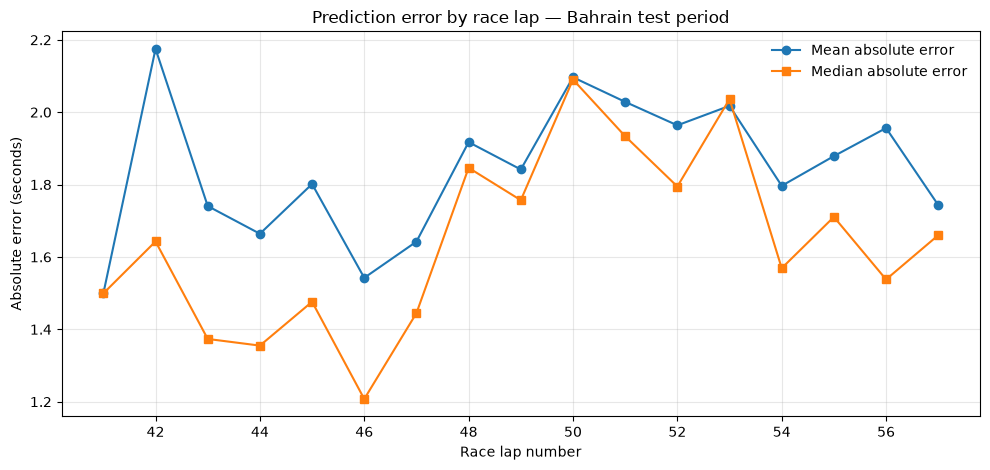

,count,mean,median
LapNumber,,,
41.0,1,1.499,1.499
42.0,14,2.175,1.643
43.0,16,1.741,1.373
44.0,16,1.664,1.355
45.0,17,1.802,1.476
46.0,17,1.542,1.208
47.0,15,1.642,1.445
48.0,16,1.917,1.846
49.0,17,1.842,1.757


In [12]:
diagnostics_b = test_b[["Driver", "LapNumber", "Compound", "TyreLife"]].copy()
diagnostics_b["ActualSeconds"] = actual_b
diagnostics_b["PredictedSeconds"] = pred_b
diagnostics_b["ResidualSeconds"] = residual_b
diagnostics_b["AbsoluteErrorSeconds"] = abs_error_b

by_lap = diagnostics_b.groupby("LapNumber")["AbsoluteErrorSeconds"].agg(["count", "mean", "median"])
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(by_lap.index, by_lap["mean"], marker="o", label="Mean absolute error")
ax.plot(by_lap.index, by_lap["median"], marker="s", label="Median absolute error")
ax.set_title("Prediction error by race lap — Bahrain test period")
ax.set_xlabel("Race lap number")
ax.set_ylabel("Absolute error (seconds)")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

display(by_lap.round(3))

## 13. Conclusions and next actions

Do not choose a model from one metric or one race. Record:
- which split was used,
- which rows and features were used,
- the baseline comparison,
- observed residual patterns,
- limitations and likely next investigations.

The previously recorded experiments showed that the median baseline beat linear regression. We should now inspect these plots, validate feature timing, clarify pit-lap handling, and expand race coverage. We should not tune repeatedly against the final test set.